In [ ]:
import pandas as pd
import numpy as np
import pickle
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score
from xgboost import XGBClassifier


df = pd.read_csv("../data/telco_churn_raw.csv")
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df = df.dropna(subset=['TotalCharges'])
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})
df = df.drop('customerID', axis=1)

X = pd.get_dummies(df.drop('Churn', axis=1), drop_first=True)
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [2]:
model_weighted = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
model_weighted.fit(X_train_scaled, y_train)
y_pred_w = model_weighted.predict(X_test_scaled)

print("Weighted Logistic Regression:")
print(f"  Accuracy:  {accuracy_score(y_test, y_pred_w):.4f}")
print(f"  Precision: {precision_score(y_test, y_pred_w):.4f}")
print(f"  Recall:    {recall_score(y_test, y_pred_w):.4f}")
print(f"  F1:        {f1_score(y_test, y_pred_w):.4f}")

Weighted Logistic Regression:
  Accuracy:  0.7264
  Precision: 0.4909
  Recall:    0.7968
  F1:        0.6075


In [3]:
rf = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)   
y_pred_rf = rf.predict(X_test)

print("Random Forest:")
print(f"  Accuracy:  {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"  Precision: {precision_score(y_test, y_pred_rf):.4f}")
print(f"  Recall:    {recall_score(y_test, y_pred_rf):.4f}")
print(f"  F1:        {f1_score(y_test, y_pred_rf):.4f}")

Random Forest:
  Accuracy:  0.7683
  Precision: 0.5545
  Recall:    0.6524
  F1:        0.5995


In [4]:
# Compute class weight for XGBoost
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.1,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric='logloss'
)
xgb.fit(X_train, y_train)
y_pred_xgb = xgb.predict(X_test)

print("XGBoost:")
print(f"  Accuracy:  {accuracy_score(y_test, y_pred_xgb):.4f}")
print(f"  Precision: {precision_score(y_test, y_pred_xgb):.4f}")
print(f"  Recall:    {recall_score(y_test, y_pred_xgb):.4f}")
print(f"  F1:        {f1_score(y_test, y_pred_xgb):.4f}")

XGBoost:
  Accuracy:  0.7434
  Precision: 0.5120
  Recall:    0.7406
  F1:        0.6055


In [5]:
def evaluate(name, y_true, y_pred):
    return {
        'Model': name,
        'Accuracy':  accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall':    recall_score(y_true, y_pred),
        'F1':        f1_score(y_true, y_pred),
    }

# Re-predict with the baseline so we have it in this notebook too
model_baseline = LogisticRegression(max_iter=1000, random_state=42)
model_baseline.fit(X_train_scaled, y_train)
y_pred_base = model_baseline.predict(X_test_scaled)

results = pd.DataFrame([
    evaluate('Baseline LR',   y_test, y_pred_base),
    evaluate('Weighted LR',   y_test, y_pred_w),
    evaluate('Random Forest', y_test, y_pred_rf),
    evaluate('XGBoost',       y_test, y_pred_xgb),
])

results = results.set_index('Model').round(4)
print(results)

               Accuracy  Precision  Recall      F1
Model                                             
Baseline LR      0.8038     0.6476  0.5749  0.6091
Weighted LR      0.7264     0.4909  0.7968  0.6075
Random Forest    0.7683     0.5545  0.6524  0.5995
XGBoost          0.7434     0.5120  0.7406  0.6055


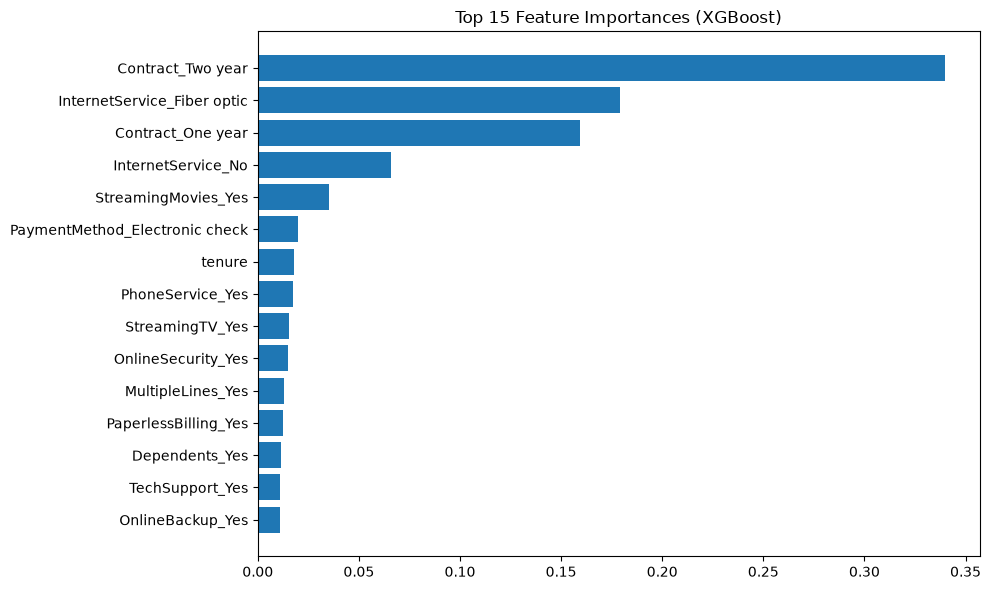

In [6]:
import matplotlib.pyplot as plt

feat_imp = pd.DataFrame({
    'feature': X_train.columns,
    'importance': xgb.feature_importances_
}).sort_values('importance', ascending=False).head(15)

plt.figure(figsize=(10, 6))
plt.barh(feat_imp['feature'], feat_imp['importance'])
plt.gca().invert_yaxis()
plt.title('Top 15 Feature Importances (XGBoost)')
plt.tight_layout()
plt.show()

In [7]:
best_model = xgb  
best_model_name = 'xgboost_final'

with open(f'../models/{best_model_name}.pkl', 'wb') as f:
    pickle.dump(best_model, f)

with open('../models/columns.pkl', 'wb') as f:
    pickle.dump(X_train.columns.tolist(), f)

print(f"Saved {best_model_name}")

Saved xgboost_final


In [8]:
import pickle

with open('../models/final_model.pkl', 'wb') as f:
    pickle.dump(model_weighted, f)

with open('../models/scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

with open('../models/columns.pkl', 'wb') as f:
    pickle.dump(X_train.columns.tolist(), f)

print("Saved final_model, scaler, columns")

Saved final_model, scaler, columns
